# Lesson 2 — Tokenization: text to numbers

⏱ **Duration:** ~25 min &nbsp;|&nbsp; 📚 **Builds on:** Lesson 1 &nbsp;|&nbsp; 💻 **Runs on:** a laptop CPU

**By the end of this lesson you will be able to:**

- split text into tokens and map them to ids
- explain the trade-off between vocabulary size, unknown words and model cost
- use the special tokens `<pad> <unk> <bos> <eos>`

> 🎤 *Teaching tip:* run the cells in order; every code cell is short enough to be explained live.

## 1. Why tokenize?

Neural networks work on numbers. A **tokenizer** converts text → list of integers (*encode*) and back (*decode*).

Three common designs:

| level | example for `unhappiness` | vocabulary | sequence length |
|-------|---------------------------|-----------|-----------------|
| characters | `u n h a p p i n e s s` | tiny (~100) | very long |
| **words** (this course) | `unhappiness` | large (10⁴–10⁵) | short |
| subwords (BPE, used by GPT-4 etc.) | `un happi ness` | medium (30k–100k) | medium |

We use **words** because it is the easiest to understand and read.

In [1]:
import sys, warnings
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))  # lets us `import myllm` without installing it

import torch
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
torch.set_num_threads(4)
DATA = ROOT / "data" / "raw"       # training text lives here
MODELS = ROOT / "models"           # checkpoints are written here

In [2]:
from myllm.data import load_corpus
from myllm.tokenizer import WordTokenizer, split_words, SPECIALS
corpus = load_corpus(DATA)

## 2. Splitting text: lowercase, words and punctuation

In [3]:
sentence = "In the beginning God created the heaven and the earth. Don't panic!"
print(split_words(sentence))

['in', 'the', 'beginning', 'god', 'created', 'the', 'heaven', 'and', 'the', 'earth', '.', "don't", 'panic', '!']


Rules (one regex in `tokenizer.py`): lowercase everything, keep contractions (`don't`) together, and make every punctuation mark its **own** token
so the model can learn where sentences end.

## 3. Building the vocabulary

We count every token and keep the **most frequent** ones. Ids `0–3` are reserved for special tokens:

| id | token | purpose |
|----|-------|---------|
| 0 | `<pad>` | padding (unused here, reserved) |
| 1 | `<unk>` | any word *not* in the vocabulary |
| 2 | `<bos>` | beginning of sequence — our generation prompt starts with it |
| 3 | `<eos>` | end of sequence (reserved) |

In [4]:
tok = WordTokenizer.train(corpus, vocab_size=4000)
print("vocabulary size:", tok.vocab_size)
print("first 25 entries:", tok.itos[:25])

vocabulary size: 4000
first 25 entries: ['<pad>', '<unk>', '<bos>', '<eos>', ',', 'the', 'and', ':', 'of', '.', 'to', 'in', 'that', 'a', 'he', ';', 'for', 'shall', 'is', 'unto', 'i', '=', 'his', 'be', 'lord']


## 4. Encode and decode

In [5]:
text = "And God said, Let there be light: and there was light."
ids = tok.encode(text)
print("ids    :", ids)
print("tokens :", [tok.itos[i] for i in ids])
print("decoded:", tok.decode(ids))
print()
print("unknown word ->", tok.encode("blockchain xylophonic"), "(1 means <unk>)")

ids    : [6, 39, 48, 4, 116, 69, 23, 434, 7, 6, 69, 34, 434, 9]
tokens : ['and', 'god', 'said', ',', 'let', 'there', 'be', 'light', ':', 'and', 'there', 'was', 'light', '.']
decoded: and god said, let there be light: and there was light.

unknown word -> [398, 1] (1 means <unk>)


Note that decoding is **lossy**: capitalisation is gone and unknown words become `<unk>`.
That is the price of a small, fast vocabulary.

## 5. Vocabulary size trade-off — measured

A bigger vocabulary means fewer `<unk>` (the model "sees" more of the text) but a bigger output layer
(one score for *every* word at *every* position) which slows training. Let's measure both.

vocab    500:  18.8% unknown,   134 ms/step
vocab   1000:  12.8% unknown,   115 ms/step
vocab   2000:   8.0% unknown,   124 ms/step
vocab   4000:   4.1% unknown,   176 ms/step
vocab   8000:   1.6% unknown,   230 ms/step
vocab  16000:   0.3% unknown,   416 ms/step


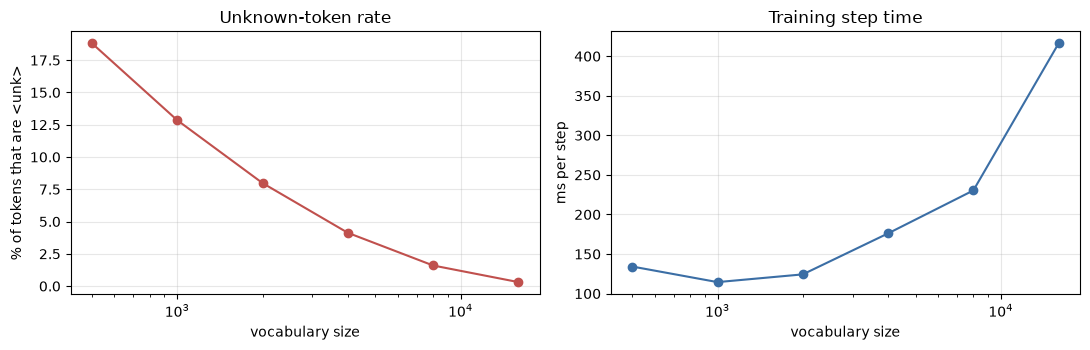

In [6]:
import time
from myllm.model import GPT, GPTConfig

all_tokens = split_words(corpus)
sizes = [500, 1000, 2000, 4000, 8000, 16000]
unk_rate, step_ms = [], []
for v in sizes:
    t = WordTokenizer.train(corpus, v)
    ids = t.encode(corpus)
    unk_rate.append(100 * sum(1 for i in ids if i == t.unk_id) / len(ids))
    m = GPT(GPTConfig(vocab_size=v, n_layer=3, n_head=4, n_embd=128, block_size=64))
    opt = torch.optim.AdamW(m.parameters()); x = torch.randint(0, v, (16, 64))
    for k in range(6):
        if k == 2: t0 = time.time()
        _, loss = m(x, x); opt.zero_grad(); loss.backward(); opt.step()
    step_ms.append((time.time() - t0) / 4 * 1000)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(sizes, unk_rate, "o-", color="#c0504d"); ax[0].set(xscale="log", title="Unknown-token rate", xlabel="vocabulary size", ylabel="% of tokens that are <unk>")
ax[1].plot(sizes, step_ms, "o-", color="#3b6ea5"); ax[1].set(xscale="log", title="Training step time", xlabel="vocabulary size", ylabel="ms per step")
plt.tight_layout()
for v, u, s in zip(sizes, unk_rate, step_ms):
    print(f"vocab {v:6d}: {u:5.1f}% unknown, {s:5.0f} ms/step")

> 💬 **Discussion:** we chose **4,000** for the default preset: ~5 % unknown, fast enough to finish ~2,500 steps in 10 minutes.
> Pick the knee of the curve for *your* time budget.

## 6. Saving the tokenizer

A model is useless without *its* tokenizer (id 57 must mean the same word at inference time).
That's why our checkpoints store the vocabulary inside the model file. You can also save it alone:

In [7]:
tok.save(MODELS / "lesson_tokenizer.json")
assert WordTokenizer.load(MODELS / "lesson_tokenizer.json").itos == tok.itos
print("saved and reloaded identically")

saved and reloaded identically


---
## ✅ Key takeaways

- Tokenization maps text to integer ids; the model never sees words, only ids.
- Vocabulary size trades coverage (fewer `<unk>`) against compute (bigger output layer).
- The tokenizer is part of the model: ship them together.

## 🧪 Exercises

1. Find the 10 most frequent tokens that are *not* words. What do they tell you about the text?
2. What is the unknown-token rate of the *Bitcoin* book alone with a vocabulary built from the *Bible*? Explain.
3. Implement a character-level tokenizer in 10 lines and compare sequence lengths for the same sentence.

## ➡️ Next

**Lesson 3 — Model architecture:** what happens to those ids inside the GPT.